# Part-of-Speech Tagging: HMM (AML) vs BiLSTM (DL)

**Task.** Assign a Universal POS (UPOS) tag to every word, on the Universal Dependencies **English EWT** treebank (official train / dev / test split).

**Story of the project.**
- **AML baseline:** an HMM with smoothing, decoded with Viterbi. Its weaknesses are a short (first-order) context and unknown words.
- **DL model:** a BiLSTM tagger that reads the sentence in both directions and adds **character-level** features, so it can guess tags for words it has never seen.
- **Question we answer with numbers:** does the neural model fix the HMM's weaknesses, and which ingredient (character features, bidirectionality, recurrence) is responsible?

| Section | What happens | Uses TEST? |
|---|---|---|
| 0 | Setup (clone repo, install, config) | no |
| 1 | Sanity run (is the pipeline healthy?) | no |
| 2 | Hyper-parameter tuning | **no (dev only)** |
| 3 | Final runs: word-only vs word+char, several seeds | **yes, once** |
| 4 | HMM vs BiLSTM, same data and same metrics | yes (reads saved predictions) |
| 5 | Error analysis (per-tag, confusion, examples) | yes (reads saved predictions) |
| 6 | Optional: architecture ladder (RNN, LSTM, GRU, CNN) | yes |
| 7 | Save and download results | no |

**Ground rules (these make the comparison fair).**
1. Vocabulary is built from the **train split only**. Words seen once in train become `<UNK>`, exactly like the HMM.
2. All tuning decisions use the **dev** set. The **test** set is evaluated only after the configuration is frozen.
3. "Unknown word" means the same thing for both models: a lowercased word form that never appears in train. Metrics come from the same functions used in the AML phase.
4. Every BiLSTM number is a **mean ± std over several random seeds**, never a single lucky run.

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Each training run takes roughly 20-40 seconds on a T4.

## 0. Setup

Start from a clean copy of the repository every session. Colab runtimes are temporary, so this cell is the first thing to re-run after a disconnect.

The notebook runs the code on the `bilstm-model` branch. Once that branch is merged, change it to `main`.

In [ ]:
%cd /content
!rm -rf POS_tagging
!git clone https://github.com/itsabhi-21/POS_tagging.git
%cd POS_tagging
!git checkout bilstm-model
!pip install -e . -q

/content
Cloning into 'POS_tagging'...
remote: Enumerating objects: 146, done.
remote: Counting objects: 100% (146/146), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 146 (delta 38), reused 115 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (146/146), 5.30 MiB | 20.09 MiB/s, done.
Resolving deltas: 100% (38/38), done.
/content/POS_tagging
branch 'bilstm-model' set up to track 'origin/bilstm-model'.
Switched to a new branch 'bilstm-model'
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for hmm-tagger (pyproject.toml) ... done


### Imports and configuration

`QUICK_TEST = True` shrinks every run to 300 sentences and 2 epochs. Use it once to check that all cells run without errors, then set it back to `False` for the real experiments.

All experiments share one training budget (`EPOCHS`, `PATIENCE`), so tuning runs and final runs are directly comparable. Early stopping looks at **dev accuracy** only.

In [ ]:
import itertools, json, os, subprocess, sys
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

QUICK_TEST = False          # True = tiny smoke test, False = real experiments

EPOCHS, PATIENCE = (2, 100) if QUICK_TEST else (40, 5)
SUBSET = 300 if QUICK_TEST else 0                  # 0 = use the full train split
SEEDS = [1, 2] if QUICK_TEST else [1, 2, 3, 4, 5]  # final runs are repeated over these seeds

os.makedirs("figures", exist_ok=True)
print("GPU available:", torch.cuda.is_available())
print("EPOCHS", EPOCHS, "| PATIENCE", PATIENCE, "| SUBSET", SUBSET, "| SEEDS", SEEDS)

GPU available: True
EPOCHS 40 | PATIENCE 5 | SUBSET 0 | SEEDS [1, 2, 3, 4, 5]


### Helper: run one experiment

`run_exp` calls `python -m bilstm_tagger.run` (the same command-line script we tested locally), hides the per-epoch log, and returns the result dictionary that the script saves as JSON. Calling the script through `subprocess` keeps every run isolated: separate process, fresh random state, no leaked GPU memory.

In [ ]:
def run_exp(out_dir, **flags):
    """Run one experiment through run.py and return its saved result dict."""
    cmd = [sys.executable, "-m", "bilstm_tagger.run", "--out_dir", out_dir,
           "--epochs", str(EPOCHS), "--patience", str(PATIENCE)]
    if SUBSET:
        cmd += ["--subset", str(SUBSET)]
    for key, val in flags.items():
        if key == "eval_test":
            if val: cmd.append("--eval_test")
        elif isinstance(val, bool):
            cmd.append(f"--{key}" if val else f"--no-{key}")
        else:
            cmd += [f"--{key}", str(val)]
    p = subprocess.run(cmd, capture_output=True, text=True)
    if p.returncode != 0:
        raise RuntimeError(p.stderr[-2000:])
    first = next(l for l in p.stdout.splitlines() if l.startswith("run:"))
    name = first.split("run: ")[1].split(" |")[0]
    return json.load(open(f"{out_dir}/{name}.json"))

## 1. Sanity run (dev only)

One run with the default settings. If the pipeline is healthy, dev accuracy should land around **95%** and unknown-word accuracy around **80%**. If it is far lower (say below 90%), stop and debug before spending time on anything else.

In [6]:
r = run_exp("results/tune/base", seed=1)
print({k: round(v, 4) for k, v in r["dev"].items()})

{'accuracy': 0.9516, 'macro_f1': 0.9106, 'unknown_accuracy': 0.808, 'n_unknown_tokens': 1708}


## 2. Hyper-parameter tuning (dev only)

We try 8 combinations of hidden size, dropout and learning rate for the main model (BiLSTM + characters), each with one seed. **No test data is used in this section.** Each combination writes into its own folder, so no run overwrites another.

In [7]:
grid = list(itertools.product([128, 256], [0.33, 0.5], [1e-3, 3e-3]))   # hidden, dropout, lr
rows = []
for hidden, dropout, lr in grid:
    r = run_exp(f"results/tune/h{hidden}_d{dropout}_lr{lr}", hidden=hidden, dropout=dropout, lr=lr, seed=1)
    rows.append({"hidden": hidden, "dropout": dropout, "lr": lr,
                 "dev_acc": r["dev"]["accuracy"], "dev_macro_f1": r["dev"]["macro_f1"],
                 "dev_unk_acc": r["dev"]["unknown_accuracy"]})
    print(rows[-1])

tune_df = pd.DataFrame(rows).sort_values("dev_acc", ascending=False).reset_index(drop=True)
tune_df.round(4)

{'hidden': 128, 'dropout': 0.33, 'lr': 0.001, 'dev_acc': 0.9514474312072531, 'dev_macro_f1': 0.9092087578078819, 'dev_unk_acc': 0.7985948477751756}
{'hidden': 128, 'dropout': 0.33, 'lr': 0.003, 'dev_acc': 0.9512883728328296, 'dev_macro_f1': 0.9098476413232819, 'dev_unk_acc': 0.7985948477751756}
{'hidden': 128, 'dropout': 0.5, 'lr': 0.001, 'dev_acc': 0.9463973278193097, 'dev_macro_f1': 0.890985636262024, 'dev_unk_acc': 0.7985948477751756}
{'hidden': 128, 'dropout': 0.5, 'lr': 0.003, 'dev_acc': 0.947948146969938, 'dev_macro_f1': 0.8972323511497147, 'dev_unk_acc': 0.7968384074941453}
{'hidden': 256, 'dropout': 0.33, 'lr': 0.001, 'dev_acc': 0.9535151900747575, 'dev_macro_f1': 0.911406851535428, 'dev_unk_acc': 0.8190866510538641}
{'hidden': 256, 'dropout': 0.33, 'lr': 0.003, 'dev_acc': 0.9527596627962462, 'dev_macro_f1': 0.9063112181657815, 'dev_unk_acc': 0.8114754098360656}
{'hidden': 256, 'dropout': 0.5, 'lr': 0.001, 'dev_acc': 0.9527198982026404, 'dev_macro_f1': 0.9060261323546654, 'dev_

,hidden,dropout,lr,dev_acc,dev_macro_f1,dev_unk_acc
0,256,0.33,0.001,0.9535,0.9114,0.8191
1,256,0.33,0.003,0.9528,0.9063,0.8115
2,256,0.50,0.001,0.9527,0.9060,0.8126
3,128,0.33,0.001,0.9514,0.9092,0.7986
4,128,0.33,0.003,0.9513,0.9098,0.7986
5,256,0.50,0.003,0.9505,0.9036,0.8097
6,128,0.50,0.003,0.9479,0.8972,0.7968
7,128,0.50,0.001,0.9464,0.8910,0.7986


### Choose the configuration

The winner is the row with the highest **dev accuracy**. Keep two cautions in mind when you read the table:
- With one seed per setting, differences below roughly 0.2 percentage points are within seed-to-seed noise. If several rows are that close, any of them is a defensible choice (prefer the smaller model).
- Once the configuration is frozen here, **do not change it after looking at test results.** That would be tuning on the test set.

In [8]:
best = tune_df.iloc[0]
best_cfg = {"hidden": int(best.hidden), "dropout": float(best.dropout), "lr": float(best.lr)}
print("Frozen configuration:", best_cfg)

Frozen configuration: {'hidden': 256, 'dropout': 0.33, 'lr': 0.001}


## 3. Final runs (the only place TEST is evaluated)

Two models, identical in every way except the character features:

- **BiLSTM word-only:** word embeddings only.
- **BiLSTM word+char:** word embeddings plus a character CNN (our final model).

Each is trained over all seeds in `SEEDS` with the frozen configuration. `eval_test=True` makes `run.py` evaluate on the test split once and save the predictions (`preds_*_test.json`) in the original sentence order, which the comparison and error analysis below use.

In [9]:
for seed in SEEDS:
    for tag, use_char in [("char", True), ("word", False)]:
        r = run_exp("results/dl", seed=seed, use_char=use_char, eval_test=True, **best_cfg)
        print(f"seed {seed} | {tag:4s} | dev acc {r['dev']['accuracy']:.4f} | test acc {r['test']['accuracy']:.4f}")

seed 1 | char | dev acc 0.9536 | test acc 0.9548
seed 1 | word | dev acc 0.9208 | test acc 0.9230
seed 2 | char | dev acc 0.9542 | test acc 0.9548
seed 2 | word | dev acc 0.9209 | test acc 0.9231
seed 3 | char | dev acc 0.9528 | test acc 0.9544
seed 3 | word | dev acc 0.9210 | test acc 0.9237
seed 4 | char | dev acc 0.9528 | test acc 0.9525
seed 4 | word | dev acc 0.9209 | test acc 0.9258
seed 5 | char | dev acc 0.9507 | test acc 0.9503
seed 5 | word | dev acc 0.9205 | test acc 0.9204


## 4. HMM vs BiLSTM on the same test set

We retrain the **HMM from the AML phase** (final "v2" settings with unknown-word shape buckets) on the same train split, then score **all models from their saved predictions with one metric function**. That guarantees an identical definition of "unknown word" for every row.

- **Token accuracy:** share of tokens tagged correctly.
- **Macro F1:** average F1 across the 17 UPOS tags, so rare tags count as much as frequent ones.
- **Unknown-word accuracy:** accuracy on tokens whose lowercased form never appears in train. This is where the HMM struggles and where character features should help.

Sanity check: the HMM's test accuracy should match the AML report (about 92.2%).

In [11]:
import os, sys
os.chdir("/content/POS_tagging")
sys.path.insert(0, "/content/POS_tagging/src")

In [13]:
from hmm_tagger import HMMTagger
from hmm_tagger.data import load_ewt
from hmm_tagger.evaluate import gold_tags, token_accuracy, macro_f1, unseen_mask, unknown_word_accuracy

data = load_ewt("data")
train, dev, test = data["train"], data["dev"], data["test"]
gold_test = gold_tags(test)

hmm = HMMTagger(shape_unk=True).fit(train)       # final HMM from the AML phase
labels = hmm.tags
hmm_pred = hmm.predict_many(test)

def evaluate_preds(pred, sents=test, train_words=hmm.train_words):
    mask = unseen_mask(sents, train_words)
    gold = gold_tags(sents)
    return {"accuracy": token_accuracy(gold, pred),
            "macro_f1": macro_f1(gold, pred, labels),
            "unknown_accuracy": unknown_word_accuracy(gold, pred, mask)}

def load_preds(prefix, seed, folder="results/dl"):
    return json.load(open(f"{folder}/preds_{prefix}-seed{seed}_test.json"))

def mean_std(pred_lists):
    rs = [evaluate_preds(p) for p in pred_lists]
    return {k: f"{100*np.mean([r[k] for r in rs]):.2f} ± {100*np.std([r[k] for r in rs]):.2f}" for k in rs[0]}

hmm_res = evaluate_preds(hmm_pred)
print("HMM test accuracy:", round(hmm_res["accuracy"], 4), "(AML report: 0.9224)")

compare = pd.DataFrame({
    "HMM + Viterbi (AML)": {k: f"{100*v:.2f}" for k, v in hmm_res.items()},
    "BiLSTM word-only":    mean_std([load_preds("lstm-bi-word", s) for s in SEEDS]),
    "BiLSTM word+char":    mean_std([load_preds("lstm-bi-char", s) for s in SEEDS]),
}).T
compare.columns = ["Token acc (%)", "Macro F1 (%)", "Unknown-word acc (%)"]
compare

HMM test accuracy: 0.9224 (AML report: 0.9224)


,Token acc (%),Macro F1 (%),Unknown-word acc (%)
HMM + Viterbi (AML),92.24,85.53,75.72
BiLSTM word-only,92.32 ± 0.17,86.56 ± 0.21,55.15 ± 0.72
BiLSTM word+char,95.33 ± 0.17,91.57 ± 0.42,81.40 ± 0.66


**How to read this table.**
- HMM → BiLSTM word-only shows what a neural model with wider context buys you.
- BiLSTM word-only → word+char isolates the effect of character features. The **unknown-word column** is the one to look at: words the model has never seen can only be tagged from their spelling (suffixes, capitalisation, digits, hyphens).
- `±` is the standard deviation over seeds. If a gap between two rows is smaller than the `±`, do not claim a difference.

## 5. Error analysis (seed 1, word+char model)

Averages hide *where* the models fail. Here we compare the HMM with the final BiLSTM tag by tag, look at which tags get confused, and read real sentences.

### 5a. Per-tag F1

Sorted so that the tags where the BiLSTM gains the most over the HMM come first. A negative `diff` means the HMM is better on that tag.

In [14]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

bil_pred = load_preds("lstm-bi-char", SEEDS[0])
g  = np.array([t for s in gold_test for t in s])
ph = np.array([t for s in hmm_pred  for t in s])
pb = np.array([t for s in bil_pred  for t in s])

_, _, f1_h, support = precision_recall_fscore_support(g, ph, labels=labels, zero_division=0)
_, _, f1_b, _       = precision_recall_fscore_support(g, pb, labels=labels, zero_division=0)

tag_df = pd.DataFrame({"tag": labels, "support": support,
                       "HMM_F1": f1_h, "BiLSTM_F1": f1_b, "diff": f1_b - f1_h})
tag_df.sort_values("diff", ascending=False).round(3).reset_index(drop=True)

,tag,support,HMM_F1,BiLSTM_F1,diff
0,X,42,0.067,0.295,0.228
1,SCONJ,384,0.763,0.907,0.144
2,SYM,113,0.798,0.871,0.073
3,ADV,1191,0.865,0.926,0.061
4,NUM,542,0.918,0.978,0.060
5,VERB,2605,0.913,0.964,0.051
6,PART,649,0.942,0.985,0.043
7,ADJ,1788,0.878,0.921,0.043
8,AUX,1543,0.948,0.989,0.041
9,PROPN,2075,0.848,0.880,0.033


### 5b. Confusion matrices

Each row is the true tag, each column the predicted tag, normalised per row (the diagonal is per-tag recall). Off-diagonal cells show which tags are mistaken for which.

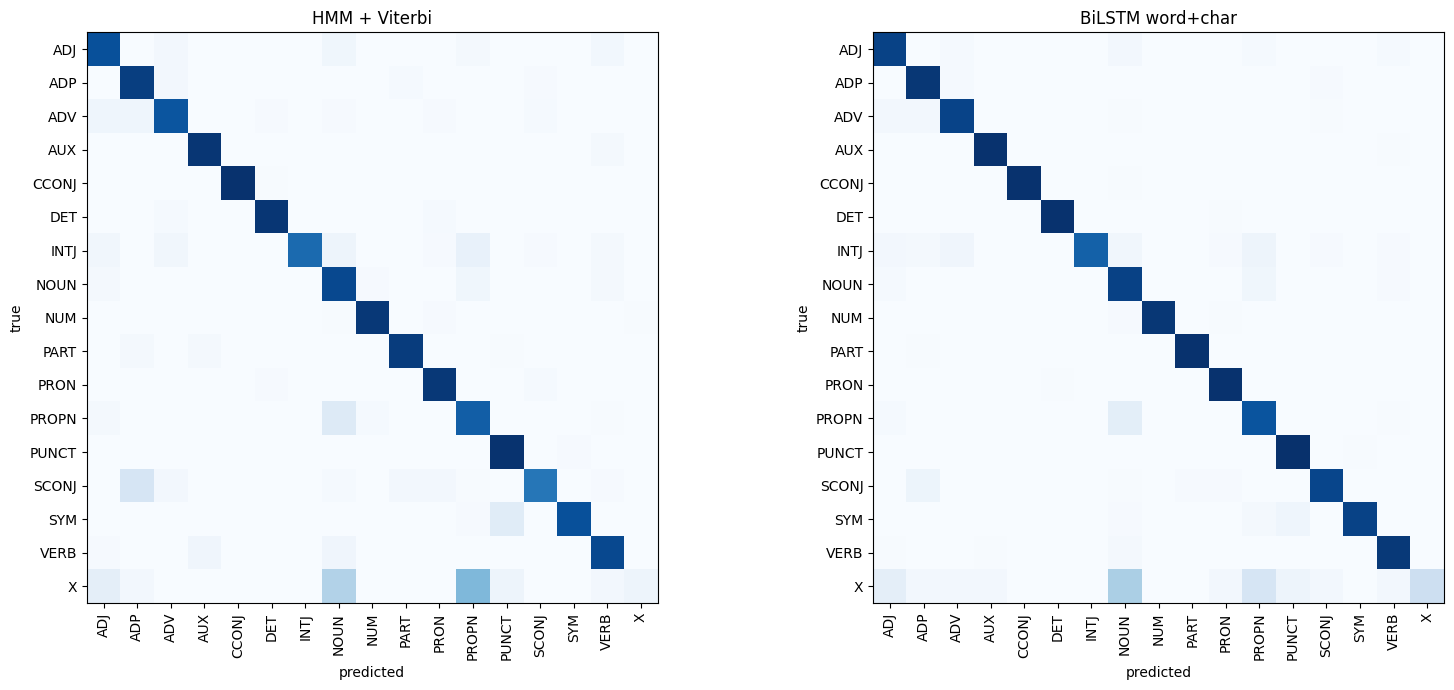

In [15]:
cm_h = confusion_matrix(g, ph, labels=labels)
cm_b = confusion_matrix(g, pb, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, cm, title in zip(axes, [cm_h, cm_b], ["HMM + Viterbi", "BiLSTM word+char"]):
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/dl_confusion_hmm_vs_bilstm.png", dpi=150)
plt.show()

### 5c. Most frequent mistakes (true tag → predicted tag)

Typical suspects in English POS tagging: `NOUN` vs `PROPN`, `ADJ` vs `NOUN`, `VERB` vs `AUX`, `ADP` vs `SCONJ`, `PRON` vs `DET`. If both models make the same mistakes, the cause is usually annotation ambiguity rather than a model weakness.

In [16]:
def top_confusions(cm, k=8):
    pairs = [(labels[i], labels[j], int(cm[i, j]))
             for i in range(len(labels)) for j in range(len(labels)) if i != j and cm[i, j] > 0]
    return pd.DataFrame(sorted(pairs, key=lambda x: -x[2])[:k], columns=["true", "predicted", "count"])

print("HMM"); display(top_confusions(cm_h))
print("BiLSTM word+char"); display(top_confusions(cm_b))

HMM


,true,predicted,count
0,PROPN,NOUN,266
1,NOUN,PROPN,156
2,VERB,NOUN,106
3,VERB,AUX,104
4,NOUN,ADJ,89
5,NOUN,VERB,84
6,ADJ,NOUN,69
7,SCONJ,ADP,63


BiLSTM word+char


,true,predicted,count
0,PROPN,NOUN,208
1,NOUN,PROPN,156
2,NOUN,ADJ,64
3,VERB,NOUN,60
4,ADJ,NOUN,46
5,NOUN,VERB,38
6,ADV,ADJ,32
7,PROPN,ADJ,32


### 5d. Example sentences

Tokens where one model is right and the other is wrong, shown for short sentences. `unseen=True` means the word never appeared in train.

In [17]:
unk_flags = unseen_mask(test, hmm.train_words)
offsets = np.cumsum([0] + [len(s) for s in test])

def show(win_pred, lose_pred, win_name, lose_name, n=5, max_len=20):
    shown = 0
    for i, s in enumerate(test):
        if len(s) > max_len:
            continue
        rows = [(j, w, gld) for j, (w, gld) in enumerate(s)
                if win_pred[i][j] == gld and lose_pred[i][j] != gld]
        if not rows:
            continue
        print("SENTENCE:", " ".join(w for w, _ in s))
        for j, w, gld in rows:
            print(f"   {w!r:16} gold={gld:6} {win_name}={win_pred[i][j]:6} {lose_name}={lose_pred[i][j]:6} "
                  f"unseen={bool(unk_flags[offsets[i] + j])}")
        shown += 1
        if shown == n:
            break

print("=== BiLSTM right, HMM wrong ===")
show(bil_pred, hmm_pred, "BiLSTM", "HMM")
print()
print("=== HMM right, BiLSTM wrong ===")
show(hmm_pred, bil_pred, "HMM", "BiLSTM")

=== BiLSTM right, HMM wrong ===
SENTENCE: What if Google Morphed Into GoogleOS ?
   'Morphed'        gold=VERB   BiLSTM=VERB   HMM=PROPN  unseen=True
SENTENCE: [ via Microsoft Watch from Mary Jo Foley ]
   'Watch'          gold=PROPN  BiLSTM=PROPN  HMM=VERB   unseen=False
SENTENCE: They own blogger , of course .
   'own'            gold=VERB   BiLSTM=VERB   HMM=ADJ    unseen=False
SENTENCE: Is that a money maker ?
   'that'           gold=PRON   BiLSTM=PRON   HMM=SCONJ  unseen=False
SENTENCE: Compare the flags to the Fallujah one .
   'one'            gold=NOUN   BiLSTM=NOUN   HMM=NUM    unseen=False

=== HMM right, BiLSTM wrong ===
SENTENCE: I 'm not fond of the Google - hates - privacy argument
   'hates'          gold=VERB   HMM=VERB   BiLSTM=NOUN   unseen=False
SENTENCE: But will diplomacy work ?
   'diplomacy'      gold=NOUN   HMM=NOUN   BiLSTM=VERB   unseen=False
SENTENCE: ALITO filed a dissenting opinion , in which SCALIA and THOMAS joined as to Parts I through III .
   'Parts' 

**What to write in the report from this section:**
- Which tags improved the most (likely open-class tags such as `PROPN`, `X`, `NUM`, `ADJ` that depend on spelling).
- Whether the confusion matrices show the same difficult pairs for both models.
- One or two example sentences where the BiLSTM wins because of spelling or wider context, and one where the HMM wins. An honest "where the BiLSTM still fails" example makes the analysis more convincing.

## 6. Optional: architecture ladder

Each row below changes **one thing** compared with the row before it, all with character features and the same frozen configuration:

| Step | Change | Question it answers |
|---|---|---|
| RNN (uni) | baseline recurrent net | how far does a plain RNN get? |
| LSTM (uni) | RNN → LSTM | does gating help? |
| LSTM (bi) | one direction → both directions | does right-hand context help? |
| GRU (bi) | LSTM → GRU | is the lighter gate enough? |
| CNN (window) | recurrence → convolution over a window | do we need recurrence at all? |

This section is a **bonus** and uses 3 seeds to save time. These variants were **not** tuned separately: they reuse the BiLSTM configuration, so say so in the report.

## 7. Save and download the results

The model checkpoints (`*.pt`) are large and not needed for the analysis, so they are excluded from the zip. After downloading:

1. Unzip into the repository (`results/` and `figures/` folders).
2. Commit the **JSON files, prediction files and figures**. `.pt` files are already ignored by `.gitignore`.
3. Hand `results/dl/preds_*_test.json` to the teammates who do the comparison and the error analysis. Each file is a list of sentences, and each sentence is a list of UPOS tags in the original test order, the same format as `HMMTagger.predict_many`.

Colab runtimes are deleted after a disconnect, so download before you close the tab.

In [18]:
!zip -rq dl_results.zip results figures -x "*.pt"
from google.colab import files
files.download("dl_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>